# CaloDiffusion — Electron Outlier Investigation & Layer-Profile Inspection

## Purpose

This notebook completes the **electron diagnostic follow-up** using the three fidelity ZIP files already generated (seeds `20261110`, `20261111`, `20261112`). It does **not** train the model or generate new showers.

It investigates:

1. Whether the three runs use the same checkpoint, reference events, calibration donors and geometry.
2. Which generated showers are unusual relative to the fixed reference sample at the same energy window.
3. Whether unusual showers are driven by response, occupancy, depth or radial spread.
4. How energy is distributed across the 45 active detector layers for reference, generated and scale-only showers.
5. The layer-by-layer profiles of a small set of automatically selected candidate outliers.

### Important interpretation rules

- A shower outside the reference 1st–99th percentile range is an **outlier candidate**, not automatically a faulty or unphysical shower.
- Robust-MAD scores are a second screening tool, not proof of a model defect.
- The three generation seeds are the replication units. Per-seed profiles are shown separately; pooled generated showers are descriptive and should not be treated as 1,800 independent model retrainings.
- Layer numbers are **active-layer ordinals 0–44**. No physical longitudinal distance is inferred because no validated z-coordinate table is supplied in these ZIPs.
- The reference-data independence from checkpoint training/selection remains unverified in the manifests.

## Inputs

Upload all three electron fidelity ZIP files from the controlled study. Each ZIP should contain `manifest.json`, `electron_geometry.json`, `tables/electron_all_fidelity_observables.csv`, and the native arrays under `arrays/`.


## 0. Imports and analysis settings

In [ ]:
import io, os, json, zipfile, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

EXPECTED_SEEDS = [20261110, 20261111, 20261112]
EXPECTED_PARTICLE = "electron"
EXPECTED_STRATA = ["8-12GeV", "40-60GeV", "80-120GeV"]
EXPECTED_CUTOFF_GEV = 1.51e-5  # 15.1 keV
N_LAYERS = 45
N_ANGLES = 16
N_RADIAL = 9
N_CELLS = N_LAYERS * N_ANGLES * N_RADIAL

# Outlier screening settings. These are diagnostic thresholds, not deletion rules.
REFERENCE_Q_LOW = 0.01
REFERENCE_Q_HIGH = 0.99
ROBUST_Z_THRESHOLD = 3.5
N_TOP_CANDIDATES_PER_STRATUM = 3
BOOTSTRAP_REPS = 300
ANALYSIS_RANDOM_SEED = 20261103

OUTPUT_DIR = Path("/content/electron_outlier_layer_profile_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Expected native cells:", N_CELLS)
print("Analysis cutoff:", EXPECTED_CUTOFF_GEV, "GeV (15.1 keV)")

Expected native cells: 6480
Analysis cutoff: 1.51e-05 GeV (15.1 keV)


## 1. Upload the three fidelity ZIP files

In [ ]:
from google.colab import files
uploaded = files.upload()

zip_uploads = {
    name: payload
    for name, payload in uploaded.items()
    if name.lower().endswith(".zip")
}

if len(zip_uploads) != 3:
    raise ValueError(
        f"Please upload exactly three fidelity ZIP files; received {len(zip_uploads)} ZIP file(s)."
    )

print("Uploaded ZIP files:")
for name in zip_uploads:
    print(" -", name, f"({len(zip_uploads[name])/1e6:.1f} MB)")

Saving validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip to validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip to validated_calo_controlled_electron_partition20261101_generation20261111_20261110T122815545026Z_fidelity_20261110T130201775779Z.zip
Saving validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip to validated_calo_controlled_electron_partition20261101_generation20261112_20261110T130357961245Z_fidelity_20261110T140251286095Z.zip
Uploaded ZIP files:
 - validated_calo_controlled_electron_partition20261101_generation20261110_20261110T114741139357Z_fidelity_20261110T122654678596Z.zip (44.1 MB)
 - validated_calo_co

## 2. ZIP readers and manifest checks

In [ ]:
def _zip_read_bytes(payload, suffix):
    with zipfile.ZipFile(io.BytesIO(payload)) as zf:
        matches = [n for n in zf.namelist() if n.endswith(suffix)]
        if len(matches) != 1:
            raise ValueError(
                f"Expected exactly one ZIP member ending with {suffix!r}; found {len(matches)}."
            )
        return zf.read(matches[0])


def read_json_member(payload, suffix):
    return json.loads(_zip_read_bytes(payload, suffix))


def read_csv_member(payload, suffix):
    return pd.read_csv(io.BytesIO(_zip_read_bytes(payload, suffix)))


def read_npz_member(payload, suffix):
    raw = _zip_read_bytes(payload, suffix)
    with np.load(io.BytesIO(raw), allow_pickle=False) as z:
        return {k: z[k].copy() for k in z.files}


runs = {}
for filename, payload in zip_uploads.items():
    manifest = read_json_member(payload, "manifest.json")
    seed = int(manifest["seed_streams"]["generation_seed"])
    if seed in runs:
        raise ValueError(f"Duplicate generation seed {seed}.")
    runs[seed] = {
        "filename": filename,
        "payload": payload,
        "manifest": manifest,
        "geometry": read_json_member(payload, "electron_geometry.json"),
        "gates": read_json_member(payload, "validation_gates.json"),
    }

if sorted(runs) != EXPECTED_SEEDS:
    raise ValueError(
        f"Expected seeds {EXPECTED_SEEDS}, but found {sorted(runs)}."
    )

compatibility_rows = []
first = runs[EXPECTED_SEEDS[0]]["manifest"]
base_checkpoint = first["checkpoints"]["electron"]["sha256"]
base_reference = first["reference_files"]["electron"]["sha256"]
base_revision = first["revision"]
base_partition = first["partition_sha256"]["electron"]
base_donors = first["scale_donor_sha256"]["electron"]
base_cut = first["analysis_cut_GeV_overrides"]["electron"]
base_partition_seed = first["seed_streams"]["partition_seed"]
base_baseline_seed = first["seed_streams"]["baseline_seed"]
base_analysis_seed = first["seed_streams"]["analysis_seed"]

for seed, rec in sorted(runs.items()):
    m = rec["manifest"]
    gates_pass = all(bool(g.get("passed", False)) for g in rec["gates"])
    checks = {
        "particle_is_electron": m.get("particles") == ["electron"],
        "checkpoint_hash_matches": m["checkpoints"]["electron"]["sha256"] == base_checkpoint,
        "reference_hash_matches": m["reference_files"]["electron"]["sha256"] == base_reference,
        "repository_revision_matches": m["revision"] == base_revision,
        "partition_hash_matches": m["partition_sha256"]["electron"] == base_partition,
        "scale_donor_hashes_match": m["scale_donor_sha256"]["electron"] == base_donors,
        "partition_seed_matches": m["seed_streams"]["partition_seed"] == base_partition_seed,
        "baseline_seed_matches": m["seed_streams"]["baseline_seed"] == base_baseline_seed,
        "analysis_seed_matches": m["seed_streams"]["analysis_seed"] == base_analysis_seed,
        "analysis_cut_matches": np.isclose(m["analysis_cut_GeV_overrides"]["electron"], base_cut),
        "all_validation_gates_pass": gates_pass,
    }
    for name, passed in checks.items():
        compatibility_rows.append({"generation_seed": seed, "check": name, "passed": passed})

compatibility_df = pd.DataFrame(compatibility_rows)
display(compatibility_df)

if not compatibility_df["passed"].all():
    raise AssertionError("Run compatibility check failed. Inspect the table before continuing.")

print("\nAll three runs use matching checkpoint/reference/partition/donor settings.")
print("Reference unseen by checkpoint:", first.get("reference_is_unseen_by_checkpoint"))
if not first.get("reference_is_unseen_by_checkpoint", False):
    print("WARNING: reference-event independence from checkpoint training/selection is not established.")

,generation_seed,check,passed
0,20261110,particle_is_electron,True
1,20261110,checkpoint_hash_matches,True
2,20261110,reference_hash_matches,True
3,20261110,repository_revision_matches,True
4,20261110,partition_hash_matches,True
5,20261110,scale_donor_hashes_match,True
6,20261110,partition_seed_matches,True
7,20261110,baseline_seed_matches,True
8,20261110,analysis_seed_matches,True
9,20261110,analysis_cut_matches,True



All three runs use matching checkpoint/reference/partition/donor settings.
Reference unseen by checkpoint: False


## 3. Confirm that event partitions and scale-only donors are identical

In [ ]:
# Compare the actual event-partition tables, not just their manifest hashes.
partition_tables = {
    seed: read_csv_member(rec["payload"], "tables/electron_event_partitions.csv")
    for seed, rec in runs.items()
}

partition_cols = ["particle", "stratum", "partition", "row", "energy_GeV", "event_id"]
reference_partition = partition_tables[EXPECTED_SEEDS[0]][partition_cols].sort_values(
    ["stratum", "partition", "row"]
).reset_index(drop=True)

for seed in EXPECTED_SEEDS[1:]:
    candidate = partition_tables[seed][partition_cols].sort_values(
        ["stratum", "partition", "row"]
    ).reset_index(drop=True)
    pd.testing.assert_frame_equal(reference_partition, candidate, check_dtype=False)

print("PASS: event partition tables are identical across all three seeds.")
print("Partition counts:")
display(reference_partition.groupby(["stratum", "partition"]).size().unstack(fill_value=0))

# Compare actual scale-donor tables for every energy window.
donor_checks = []
for stratum in EXPECTED_STRATA:
    suffix = f"tables/electron_{stratum}_scale_donors.csv"
    donor_tables = {
        seed: read_csv_member(rec["payload"], suffix)
        for seed, rec in runs.items()
    }
    base_df = donor_tables[EXPECTED_SEEDS[0]].sort_values(
        list(donor_tables[EXPECTED_SEEDS[0]].columns)
    ).reset_index(drop=True)
    for seed in EXPECTED_SEEDS[1:]:
        other = donor_tables[seed].sort_values(
            list(donor_tables[seed].columns)
        ).reset_index(drop=True)
        pd.testing.assert_frame_equal(base_df, other, check_dtype=False)
    donor_checks.append({"stratum": stratum, "donors_identical_across_seeds": True,
                         "n_donor_rows": len(base_df)})

display(pd.DataFrame(donor_checks))
print("PASS: scale-only donor tables are identical across all three seeds.")

# Also compare the saved reference and scale-only native arrays across ZIPs.
# This confirms that the exact evaluated reference showers and baseline outputs were reused.
array_reuse_rows = []
for stratum in EXPECTED_STRATA:
    for method, suffix in [
        ("reference", f"arrays/electron_{stratum}_reference_run-1.npz"),
        ("scale_only", f"arrays/electron_{stratum}_scale_only_run-1.npz"),
    ]:
        base_arrays = read_npz_member(runs[EXPECTED_SEEDS[0]]["payload"], suffix)
        base_ids = base_arrays["event_id"].astype(str)
        base_native = base_arrays["native"]
        for seed in EXPECTED_SEEDS[1:]:
            other = read_npz_member(runs[seed]["payload"], suffix)
            assert np.array_equal(base_ids, other["event_id"].astype(str)), (
                f"{method} event IDs differ for {stratum}, seed {seed}."
            )
            assert np.array_equal(base_native, other["native"]), (
                f"{method} native arrays differ for {stratum}, seed {seed}."
            )
        array_reuse_rows.append({
            "stratum": stratum,
            "sample": method,
            "event_ids_identical": True,
            "native_arrays_identical": True,
            "n_showers": len(base_ids),
        })

display(pd.DataFrame(array_reuse_rows))
print("PASS: reference and scale-only native arrays are exactly identical across the three ZIPs.")


PASS: event partition tables are identical across all three seeds.
Partition counts:


partition,calibration,pilot,test
stratum,,,
40-60GeV,300,80,300
8-12GeV,300,80,300
80-120GeV,300,80,300


,stratum,donors_identical_across_seeds,n_donor_rows
0,8-12GeV,True,300
1,40-60GeV,True,300
2,80-120GeV,True,300


PASS: scale-only donor tables are identical across all three seeds.


,stratum,sample,event_ids_identical,native_arrays_identical,n_showers
0,8-12GeV,reference,True,True,300
1,8-12GeV,scale_only,True,True,300
2,40-60GeV,reference,True,True,300
3,40-60GeV,scale_only,True,True,300
4,80-120GeV,reference,True,True,300
5,80-120GeV,scale_only,True,True,300


PASS: reference and scale-only native arrays are exactly identical across the three ZIPs.


## 4. Load event-level observables and verify native arrays

In [ ]:
# Keep generated events from all three seeds.
# Keep the fixed reference and scale-only samples only once (from the first ZIP).
obs_by_seed = {}
generator_frames = []
reference_frames = []
scale_frames = []
layer_cols = [f"layer_fraction_{i}" for i in range(N_LAYERS)]
required_metrics = ["response", "deposited_GeV", "occupancy", "depth_layer", "r_rms", "r_sigma", "nhits"]

for seed, rec in sorted(runs.items()):
    obs = read_csv_member(rec["payload"], "tables/electron_all_fidelity_observables.csv")
    missing = [c for c in layer_cols + required_metrics + ["stratum", "method", "event_id", "run"] if c not in obs.columns]
    if missing:
        raise ValueError(f"Seed {seed}: missing columns {missing}")
    obs["generation_seed"] = seed
    obs_by_seed[seed] = obs
    generator_frames.append(obs[obs["method"] == "generator"].copy())
    if seed == EXPECTED_SEEDS[0]:
        reference_frames.append(obs[obs["method"] == "reference"].copy())
        scale_frames.append(obs[obs["method"] == "scale_only"].copy())

gen = pd.concat(generator_frames, ignore_index=True)
ref = pd.concat(reference_frames, ignore_index=True)
scale = pd.concat(scale_frames, ignore_index=True)

# The per-event layer fractions should sum to one for showers with positive deposited energy.
for name, frame in [("reference", ref), ("generator", gen), ("scale_only", scale)]:
    sums = frame[layer_cols].sum(axis=1).to_numpy()
    if not np.allclose(sums, 1.0, atol=2e-5, rtol=2e-5):
        raise AssertionError(f"Layer fractions do not sum to one for {name}.")

count_rows = []
for seed in EXPECTED_SEEDS:
    g = gen[gen.generation_seed == seed]
    for stratum in EXPECTED_STRATA:
        count_rows.append({
            "generation_seed": seed,
            "stratum": stratum,
            "reference_n": len(ref[ref.stratum == stratum]),
            "generator_n": len(g[g.stratum == stratum]),
            "scale_only_n": len(scale[scale.stratum == stratum]),
        })
counts_df = pd.DataFrame(count_rows)
display(counts_df)

# Confirm native array dimensions and event IDs can be read for each seed/energy/run.
array_check_rows = []
for seed, rec in sorted(runs.items()):
    geom = rec["geometry"]
    n_geom = sum(
        int(a) * (len(edges) - 1)
        for a, edges in zip(geom["n_angles"], geom["radial_edges"])
    )
    assert len(geom["layer_ids"]) == N_LAYERS
    assert n_geom == N_CELLS
    for stratum in EXPECTED_STRATA:
        for run_id in (0, 1):
            suffix = f"arrays/electron_{stratum}_generator_run{run_id}.npz"
            arr = read_npz_member(rec["payload"], suffix)
            assert arr["native"].shape == (300, N_CELLS)
            assert len(arr["event_id"]) == 300
            assert len(set(arr["event_id"].astype(str))) == 300
            array_check_rows.append({"seed": seed, "stratum": stratum,
                                     "run": run_id, "native_shape": str(arr["native"].shape),
                                     "unique_event_ids": 300})

display(pd.DataFrame(array_check_rows))
print("Native geometry and generated-array shapes are consistent.")

,generation_seed,stratum,reference_n,generator_n,scale_only_n
0,20261110,8-12GeV,300,600,300
1,20261110,40-60GeV,300,600,300
2,20261110,80-120GeV,300,600,300
3,20261111,8-12GeV,300,600,300
4,20261111,40-60GeV,300,600,300
5,20261111,80-120GeV,300,600,300
6,20261112,8-12GeV,300,600,300
7,20261112,40-60GeV,300,600,300
8,20261112,80-120GeV,300,600,300


,seed,stratum,run,native_shape,unique_event_ids
0,20261110,8-12GeV,0,"(300, 6480)",300
1,20261110,8-12GeV,1,"(300, 6480)",300
2,20261110,40-60GeV,0,"(300, 6480)",300
3,20261110,40-60GeV,1,"(300, 6480)",300
4,20261110,80-120GeV,0,"(300, 6480)",300
5,20261110,80-120GeV,1,"(300, 6480)",300
6,20261111,8-12GeV,0,"(300, 6480)",300
7,20261111,8-12GeV,1,"(300, 6480)",300
8,20261111,40-60GeV,0,"(300, 6480)",300
9,20261111,40-60GeV,1,"(300, 6480)",300


Native geometry and generated-array shapes are consistent.


## 5. Descriptive statistics by seed and energy window

In [ ]:
STAT_METRICS = ["response", "deposited_GeV", "occupancy", "depth_layer", "r_rms", "r_sigma"]
summary_rows = []

for stratum in EXPECTED_STRATA:
    ref_s = ref[ref.stratum == stratum]
    scale_s = scale[scale.stratum == stratum]
    groups = [("reference", "fixed", ref_s), ("scale_only", "fixed", scale_s)]
    for seed in EXPECTED_SEEDS:
        groups.append(("generator", str(seed), gen[(gen.stratum == stratum) & (gen.generation_seed == seed)]))

    for method, seed_label, frame in groups:
        for metric in STAT_METRICS:
            x = frame[metric].dropna().to_numpy(dtype=float)
            summary_rows.append({
                "stratum": stratum,
                "method": method,
                "generation_seed": seed_label,
                "observable": metric,
                "n": len(x),
                "mean": np.mean(x),
                "std": np.std(x, ddof=1),
                "q05": np.quantile(x, 0.05),
                "median": np.quantile(x, 0.50),
                "q95": np.quantile(x, 0.95),
                "q99": np.quantile(x, 0.99),
                "min": np.min(x),
                "max": np.max(x),
            })

summary_df = pd.DataFrame(summary_rows)
print("Response summary:")
display(summary_df[summary_df.observable == "response"].round(5))
print("Shape-related summary:")
display(summary_df[summary_df.observable.isin(["occupancy", "depth_layer", "r_rms", "r_sigma"])].round(4))

Response summary:


,stratum,method,generation_seed,observable,n,mean,std,q05,median,q95,q99,min,max
0,8-12GeV,reference,fixed,response,300,0.76591,0.09862,0.59649,0.76999,0.91229,0.97123,0.44040,1.02207
6,8-12GeV,scale_only,fixed,response,300,0.77728,0.04956,0.68692,0.77709,0.85354,0.88134,0.65386,0.93072
12,8-12GeV,generator,20261110,response,600,0.74607,0.11182,0.55187,0.74791,0.92274,0.97934,0.39905,1.04854
18,8-12GeV,generator,20261111,response,600,0.74606,0.11407,0.56165,0.74712,0.92020,0.96763,0.35558,1.37330
24,8-12GeV,generator,20261112,response,600,0.76132,0.10829,0.57942,0.76525,0.93896,0.99622,0.41731,1.07384
30,40-60GeV,reference,fixed,response,300,0.77308,0.04557,0.69528,0.77710,0.84309,0.86427,0.63152,0.87019
36,40-60GeV,scale_only,fixed,response,300,0.77728,0.04956,0.68692,0.77709,0.85355,0.88135,0.65388,0.93072
42,40-60GeV,generator,20261110,response,600,0.76692,0.05017,0.68196,0.76846,0.85042,0.88024,0.61633,0.93623
48,40-60GeV,generator,20261111,response,600,0.77096,0.05107,0.68824,0.77131,0.85522,0.88893,0.60482,0.91503
54,40-60GeV,generator,20261112,response,600,0.76942,0.05392,0.68119,0.77227,0.85235,0.89639,0.60065,0.99517


Shape-related summary:


,stratum,method,generation_seed,observable,n,mean,std,q05,median,q95,q99,min,max
2,8-12GeV,reference,fixed,occupancy,300,0.0697,0.0083,0.0565,0.0695,0.0829,0.0892,0.0406,0.0921
3,8-12GeV,reference,fixed,depth_layer,300,8.8560,1.9671,6.6755,8.5519,11.3659,13.3652,5.9961,31.9435
4,8-12GeV,reference,fixed,r_rms,300,10.7927,2.1412,7.8909,10.5175,14.7014,16.9375,7.1894,18.5398
5,8-12GeV,reference,fixed,r_sigma,300,8.0420,1.5356,5.9043,7.8773,10.9090,11.7700,5.0800,12.4760
8,8-12GeV,scale_only,fixed,occupancy,300,0.1969,0.0156,0.1738,0.1958,0.2213,0.2377,0.1603,0.2486
9,8-12GeV,scale_only,fixed,depth_layer,300,10.7558,1.2456,9.0434,10.5400,13.1731,14.0212,8.0048,16.9556
10,8-12GeV,scale_only,fixed,r_rms,300,10.9236,0.9418,9.4449,10.9221,12.4499,13.0793,8.5926,14.0672
11,8-12GeV,scale_only,fixed,r_sigma,300,8.2382,0.6917,7.1684,8.2540,9.3765,9.8396,6.4326,10.5003
14,8-12GeV,generator,20261110,occupancy,600,0.0688,0.0090,0.0548,0.0684,0.0840,0.0911,0.0480,0.0975
15,8-12GeV,generator,20261110,depth_layer,600,8.5786,1.3133,6.8001,8.4223,10.7245,11.8518,5.5930,22.5278


## 6. Outlier screening against the fixed reference

For each energy window and each observable, the reference sample defines:

- the empirical 1st and 99th percentile interval;
- the reference median and median absolute deviation (MAD).

A generated shower is flagged if it falls outside the reference 1st–99th percentile interval for at least one metric, or has an absolute robust z-score above 3.5 for at least one metric.

This is a **screening procedure**. It identifies showers worth inspecting; it does not label them unphysical.

In [ ]:
OUTLIER_METRICS = ["response", "deposited_GeV", "occupancy", "depth_layer", "r_rms", "r_sigma"]
reference_limits = {}
for stratum in EXPECTED_STRATA:
    r = ref[ref.stratum == stratum]
    for metric in OUTLIER_METRICS:
        x = r[metric].dropna().to_numpy(dtype=float)
        med = float(np.median(x))
        mad = float(np.median(np.abs(x - med)))
        robust_scale = 1.4826 * mad
        reference_limits[(stratum, metric)] = {
            "q_low": float(np.quantile(x, REFERENCE_Q_LOW)),
            "q_high": float(np.quantile(x, REFERENCE_Q_HIGH)),
            "median": med,
            "mad": mad,
            "robust_scale": robust_scale,
        }

metric_flag_rows = []
candidate_rows = []
for _, row in gen.iterrows():
    stratum = row["stratum"]
    flags = []
    z_scores = {}
    for metric in OUTLIER_METRICS:
        lim = reference_limits[(stratum, metric)]
        value = float(row[metric])
        low_flag = value < lim["q_low"]
        high_flag = value > lim["q_high"]
        scale_value = lim["robust_scale"]
        rz = ((value - lim["median"]) / scale_value) if scale_value > 0 else np.nan
        z_scores[metric] = rz
        if low_flag or high_flag:
            flags.append(metric)
        metric_flag_rows.append({
            "generation_seed": int(row["generation_seed"]),
            "stratum": stratum,
            "metric": metric,
            "reference_q01": lim["q_low"],
            "reference_q99": lim["q_high"],
            "below_reference_q01": bool(low_flag),
            "above_reference_q99": bool(high_flag),
            "outside_reference_envelope": bool(low_flag or high_flag),
            "robust_z": rz,
            "robust_z_abs_gt_3p5": bool(np.isfinite(rz) and abs(rz) > ROBUST_Z_THRESHOLD),
        })
    finite_abs_z = [abs(v) for v in z_scores.values() if np.isfinite(v)]
    max_abs_z = max(finite_abs_z) if finite_abs_z else np.nan
    if flags or (np.isfinite(max_abs_z) and max_abs_z > ROBUST_Z_THRESHOLD):
        candidate_rows.append({
            "generation_seed": int(row["generation_seed"]),
            "stratum": stratum,
            "run": int(row["run"]),
            "event_id": str(row["event_id"]),
            "flagged_metrics_outside_q01_q99": ";".join(flags),
            "max_abs_reference_robust_z": max_abs_z,
            **{m: row[m] for m in OUTLIER_METRICS},
        })

metric_flags_df = pd.DataFrame(metric_flag_rows)
candidates_df = pd.DataFrame(candidate_rows)

outlier_count_rows = []
for (seed, stratum, metric), sub in metric_flags_df.groupby(["generation_seed", "stratum", "metric"]):
    outlier_count_rows.append({
        "generation_seed": seed,
        "stratum": stratum,
        "metric": metric,
        "n_generated": len(sub),
        "below_reference_q01": int(sub["below_reference_q01"].sum()),
        "above_reference_q99": int(sub["above_reference_q99"].sum()),
        "outside_reference_q01_q99": int(sub["outside_reference_envelope"].sum()),
        "robust_z_abs_gt_3p5": int(sub["robust_z_abs_gt_3p5"].sum()),
    })
outlier_counts_df = pd.DataFrame(outlier_count_rows)

print("Outlier counts by metric, generation seed and energy:")
display(outlier_counts_df)
print("Candidate event count:", len(candidates_df))
display(candidates_df.sort_values(
    ["stratum", "max_abs_reference_robust_z"], ascending=[True, False]
).groupby("stratum").head(10).round(4))

Outlier counts by metric, generation seed and energy:


,generation_seed,stratum,metric,n_generated,below_reference_q01,above_reference_q99,outside_reference_q01_q99,robust_z_abs_gt_3p5
0,20261110,40-60GeV,deposited_GeV,600,13,6,19,0
1,20261110,40-60GeV,depth_layer,600,10,7,17,7
2,20261110,40-60GeV,occupancy,600,12,3,15,0
3,20261110,40-60GeV,r_rms,600,1,1,2,1
4,20261110,40-60GeV,r_sigma,600,7,2,9,1
5,20261110,40-60GeV,response,600,8,13,21,0
6,20261110,8-12GeV,deposited_GeV,600,8,9,17,0
7,20261110,8-12GeV,depth_layer,600,11,1,12,1
8,20261110,8-12GeV,occupancy,600,7,9,16,0
9,20261110,8-12GeV,r_rms,600,8,2,10,0


Candidate event count: 635


,generation_seed,stratum,run,event_id,flagged_metrics_outside_q01_q99,max_abs_reference_robust_z,response,deposited_GeV,occupancy,depth_layer,r_rms,r_sigma
79,20261110,40-60GeV,0,gen:electron:40-60GeV:0:113,depth_layer,6.3300,0.7459,32.1100,0.2185,16.8456,12.3908,9.0503
105,20261110,40-60GeV,1,gen:electron:40-60GeV:1:31,depth_layer,5.5712,0.6952,35.7430,0.2329,16.0921,11.4402,8.6087
499,20261112,40-60GeV,0,gen:electron:40-60GeV:0:120,r_rms;r_sigma,5.1733,0.8040,46.7894,0.2039,8.9156,14.6682,11.2986
269,20261111,40-60GeV,0,gen:electron:40-60GeV:0:109,depth_layer,5.0728,0.8128,46.5548,0.2284,15.5972,9.6004,7.2112
322,20261111,40-60GeV,1,gen:electron:40-60GeV:1:191,depth_layer,4.8295,0.7757,33.4342,0.2284,15.3557,10.5350,7.8100
113,20261110,40-60GeV,1,gen:electron:40-60GeV:1:107,occupancy;depth_layer,4.7288,0.8006,44.8268,0.2602,15.2556,11.1773,8.4535
73,20261110,40-60GeV,0,gen:electron:40-60GeV:0:49,r_rms;r_sigma,4.6694,0.8079,34.4671,0.1819,10.3306,14.3307,10.9859
104,20261110,40-60GeV,1,gen:electron:40-60GeV:1:29,depth_layer,4.5166,0.8198,39.9777,0.2082,15.0450,9.4736,7.2199
515,20261112,40-60GeV,0,gen:electron:40-60GeV:0:274,response;r_rms;r_sigma,4.4928,0.9952,41.7757,0.1731,8.7108,8.9279,6.6829
343,20261111,40-60GeV,1,gen:electron:40-60GeV:1:296,r_rms;r_sigma,4.4924,0.7472,34.9445,0.2000,10.3986,14.3939,10.8761


## 7. Explicit extreme-event table

In [ ]:
# Independently list min/max response, shallowest/deepest shower,
# and narrowest/widest radial RMS for each seed and energy window.
EXTREME_METRICS = ["response", "depth_layer", "r_rms", "occupancy"]
extreme_rows = []

for seed in EXPECTED_SEEDS:
    for stratum in EXPECTED_STRATA:
        sub = gen[(gen.generation_seed == seed) & (gen.stratum == stratum)]
        for metric in EXTREME_METRICS:
            for direction, idx in [("minimum", sub[metric].idxmin()), ("maximum", sub[metric].idxmax())]:
                row = gen.loc[idx]
                extreme_rows.append({
                    "generation_seed": seed,
                    "stratum": stratum,
                    "metric": metric,
                    "extreme": direction,
                    "event_id": row["event_id"],
                    "run": int(row["run"]),
                    **{m: row[m] for m in OUTLIER_METRICS},
                })

extremes_df = pd.DataFrame(extreme_rows)
display(extremes_df.round(5))

,generation_seed,stratum,metric,extreme,event_id,run,response,deposited_GeV,occupancy,depth_layer,r_rms,r_sigma
0,20261110,8-12GeV,response,minimum,gen:electron:8-12GeV:0:235,0,0.39905,3.56357,0.04799,8.19340,11.74636,8.93108
1,20261110,8-12GeV,response,maximum,gen:electron:8-12GeV:1:282,1,1.04854,10.07527,0.07793,8.90852,8.06493,5.80998
2,20261110,8-12GeV,depth_layer,minimum,gen:electron:8-12GeV:0:239,0,0.61632,6.35536,0.05679,5.59295,12.80408,9.87487
3,20261110,8-12GeV,depth_layer,maximum,gen:electron:8-12GeV:1:58,1,0.73501,7.64342,0.07917,22.52775,7.12754,5.32216
4,20261110,8-12GeV,r_rms,minimum,gen:electron:8-12GeV:0:164,0,0.88386,7.42127,0.07654,9.86784,6.95228,4.98911
...,...,...,...,...,...,...,...,...,...,...,...,...
67,20261112,80-120GeV,depth_layer,maximum,gen:electron:80-120GeV:1:48,1,0.78348,90.05140,0.34769,16.71212,11.02345,8.23217
68,20261112,80-120GeV,r_rms,minimum,gen:electron:80-120GeV:1:93,1,0.84951,76.37066,0.27500,11.61332,9.19848,7.00187
69,20261112,80-120GeV,r_rms,maximum,gen:electron:80-120GeV:0:99,0,0.75967,67.83184,0.27099,10.67299,12.59791,9.58153
70,20261112,80-120GeV,occupancy,minimum,gen:electron:80-120GeV:1:219,1,0.72054,59.36031,0.23704,8.71550,11.03212,8.50447


## 8. Response and observable distributions

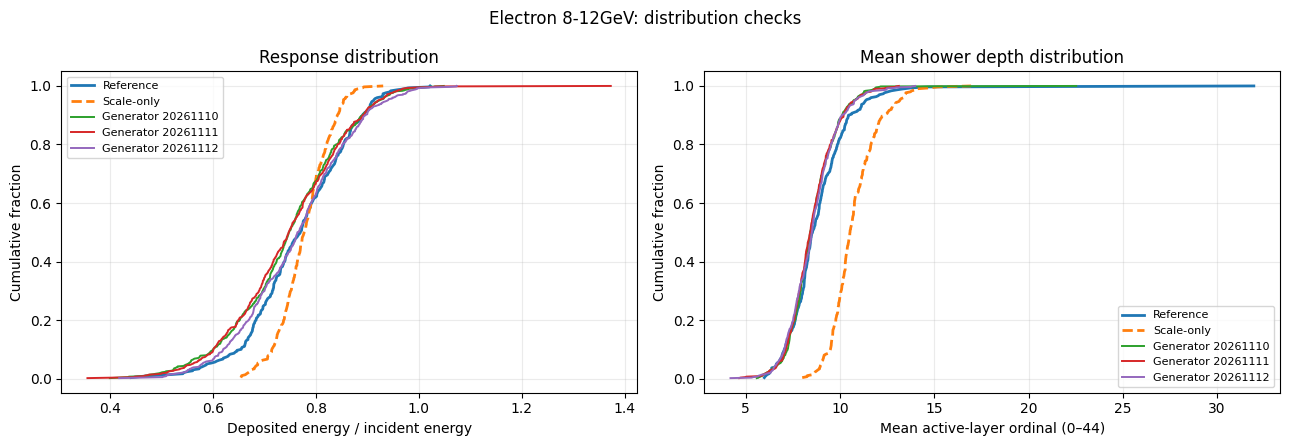

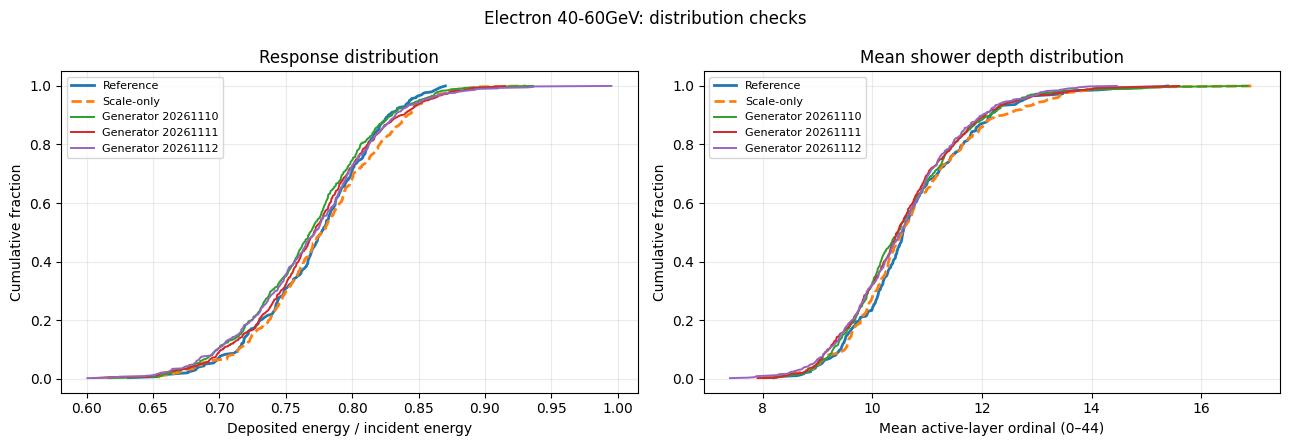

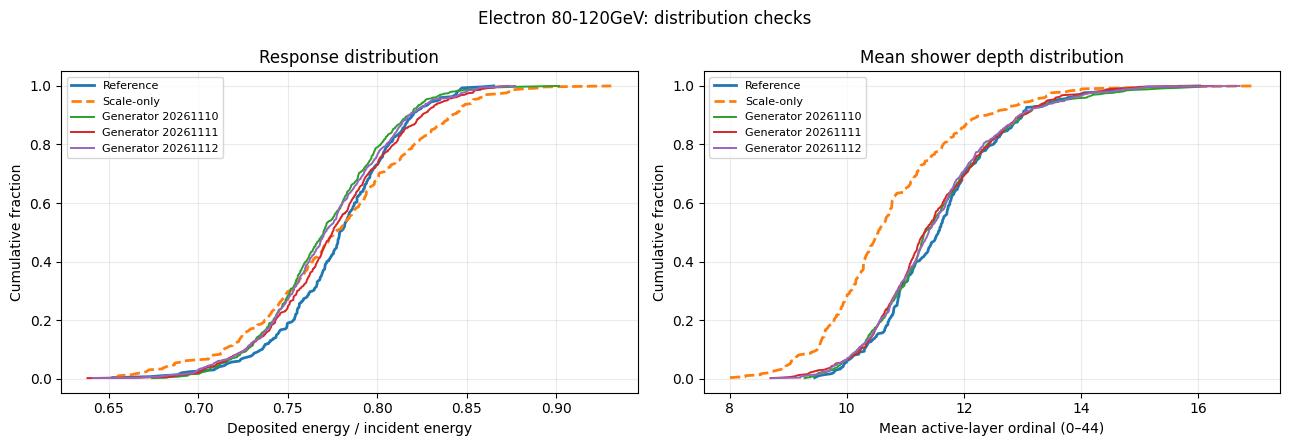

In [ ]:
# ECDF overlays: fixed reference, scale-only baseline, and each generation seed.
def ecdf(x):
    x = np.sort(np.asarray(x, dtype=float))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

for stratum in EXPECTED_STRATA:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    r = ref[ref.stratum == stratum]
    s = scale[scale.stratum == stratum]
    for ax, metric, title, xlabel in [
        (axes[0], "response", "Response distribution", "Deposited energy / incident energy"),
        (axes[1], "depth_layer", "Mean shower depth distribution", "Mean active-layer ordinal (0–44)"),
    ]:
        for label, frame, style in [
            ("Reference", r, "-"),
            ("Scale-only", s, "--"),
        ]:
            x, y = ecdf(frame[metric].dropna())
            ax.plot(x, y, linestyle=style, linewidth=2, label=label)
        for seed in EXPECTED_SEEDS:
            g = gen[(gen.stratum == stratum) & (gen.generation_seed == seed)]
            x, y = ecdf(g[metric].dropna())
            ax.plot(x, y, linewidth=1.4, label=f"Generator {seed}")
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Cumulative fraction")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"Electron {stratum}: distribution checks")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stratum.replace('-', '_')}_response_depth_ecdf.png", dpi=160)
    plt.show()

## 9. Mean layer-profile comparison

Each shower has 45 columns, `layer_fraction_0` through `layer_fraction_44`. These are the fraction of that event's thresholded deposited energy in each active detector layer. They sum to one per event.

This section compares:

- the fixed reference profile;
- scale-only profile;
- each of the three generated-seed profiles;
- a pooled generator profile for descriptive context.

The bootstrap bands are computed by resampling showers within each displayed group. They describe event-sampling uncertainty within that group; the three generation seeds are still shown separately so run-to-run variation is visible.

Layer-profile table (first rows):


,stratum,method,seed,layer_ordinal,mean_layer_fraction,std_across_showers,bootstrap_ci_low,bootstrap_ci_high,n_showers
0,8-12GeV,reference,fixed,0,0.01630,0.02313,0.01349,0.01875,300
1,8-12GeV,reference,fixed,1,0.02843,0.02781,0.02542,0.03135,300
2,8-12GeV,reference,fixed,2,0.04574,0.02940,0.04286,0.04909,300
3,8-12GeV,reference,fixed,3,0.06134,0.03139,0.05829,0.06475,300
4,8-12GeV,reference,fixed,4,0.07412,0.03139,0.07057,0.07760,300
5,8-12GeV,reference,fixed,5,0.08607,0.03179,0.08324,0.08972,300
6,8-12GeV,reference,fixed,6,0.08790,0.02705,0.08481,0.09075,300
7,8-12GeV,reference,fixed,7,0.08638,0.02603,0.08354,0.08948,300
8,8-12GeV,reference,fixed,8,0.08049,0.02566,0.07777,0.08347,300
9,8-12GeV,reference,fixed,9,0.06939,0.02191,0.06698,0.07192,300


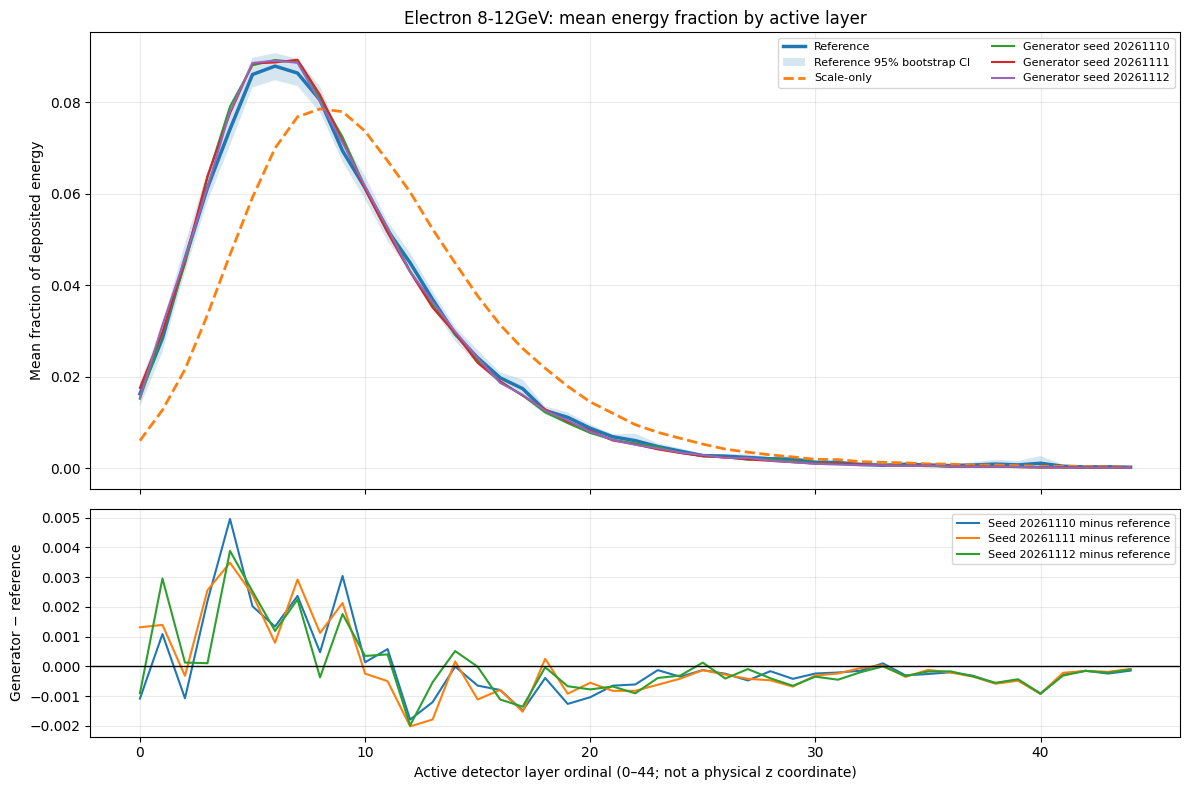

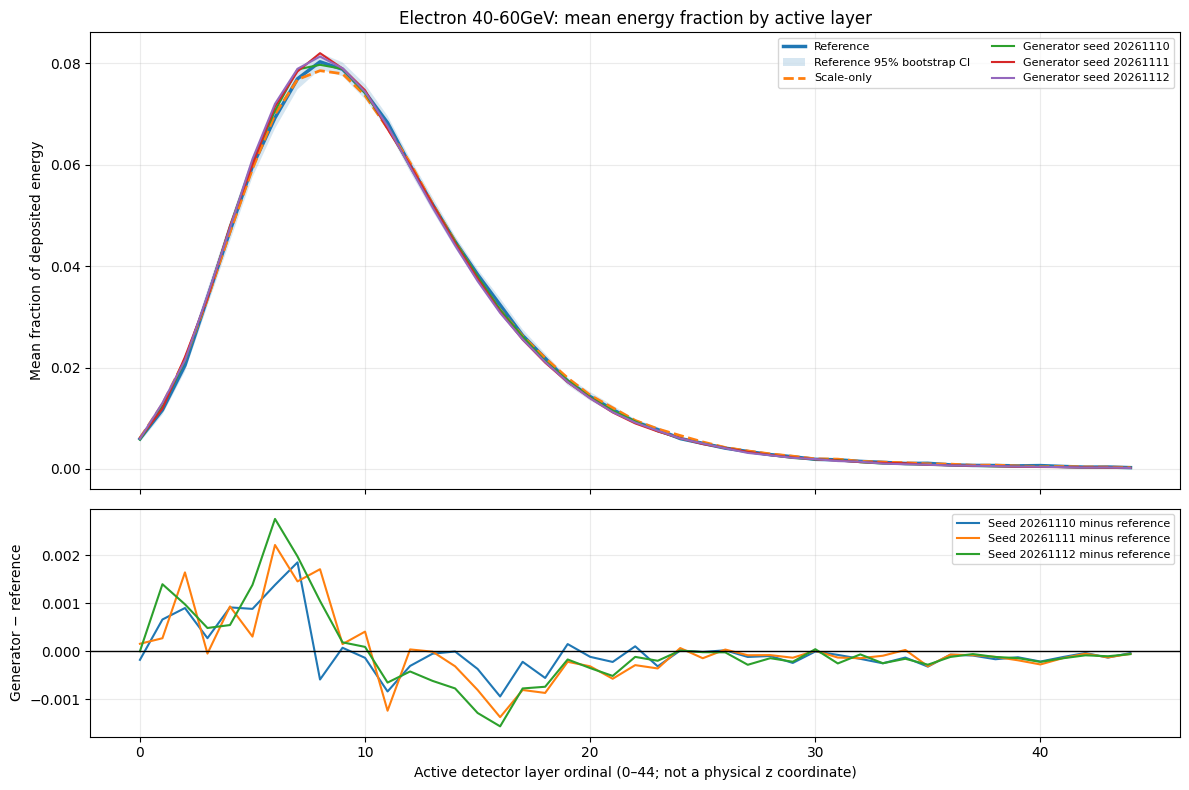

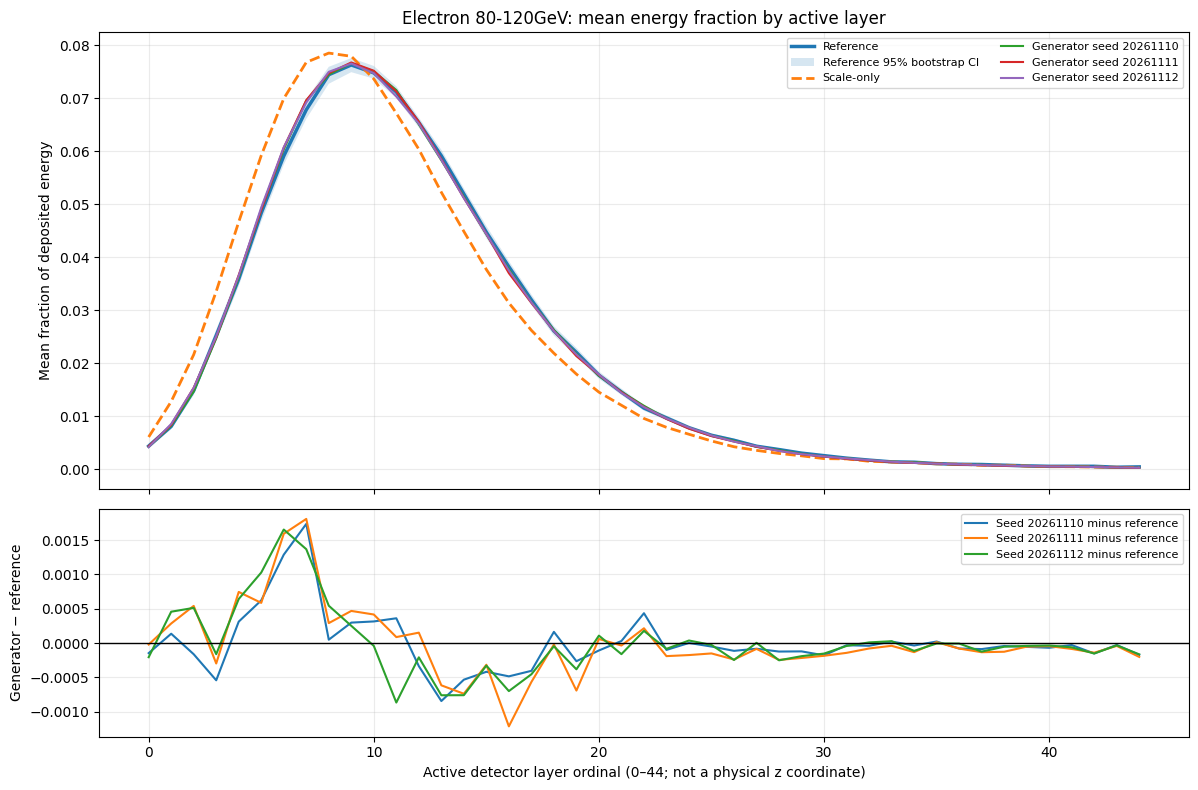

In [ ]:
rng = np.random.default_rng(ANALYSIS_RANDOM_SEED)


def bootstrap_profile_ci(frame, reps=BOOTSTRAP_REPS):
    X = frame[layer_cols].to_numpy(dtype=float)
    n = len(X)
    mean = X.mean(axis=0)
    boot = np.empty((reps, X.shape[1]), dtype=float)
    for b in range(reps):
        idx = rng.integers(0, n, size=n)
        boot[b] = X[idx].mean(axis=0)
    lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)
    return mean, X.std(axis=0, ddof=1), lo, hi


profile_records = []
profile_vectors = {}
profile_groups = {}

for stratum in EXPECTED_STRATA:
    groups = {
        "reference": ("reference", "fixed", ref[ref.stratum == stratum]),
        "scale_only": ("scale_only", "fixed", scale[scale.stratum == stratum]),
    }
    for seed in EXPECTED_SEEDS:
        groups[f"generator_{seed}"] = (
            "generator", str(seed),
            gen[(gen.stratum == stratum) & (gen.generation_seed == seed)]
        )
    groups["generator_pooled"] = (
        "generator", "pooled_3_seeds", gen[gen.stratum == stratum]
    )

    for key, (method, seed_label, frame) in groups.items():
        mean, std, lo, hi = bootstrap_profile_ci(frame)
        profile_vectors[(stratum, key)] = mean
        profile_groups[(stratum, key)] = frame
        for layer in range(N_LAYERS):
            profile_records.append({
                "stratum": stratum,
                "method": method,
                "seed": seed_label,
                "layer_ordinal": layer,
                "mean_layer_fraction": mean[layer],
                "std_across_showers": std[layer],
                "bootstrap_ci_low": lo[layer],
                "bootstrap_ci_high": hi[layer],
                "n_showers": len(frame),
            })

layer_profile_df = pd.DataFrame(profile_records)
print("Layer-profile table (first rows):")
display(layer_profile_df.head(15).round(5))

for stratum in EXPECTED_STRATA:
    ref_mean = profile_vectors[(stratum, "reference")]
    ref_lo = layer_profile_df[(layer_profile_df.stratum == stratum) &
                              (layer_profile_df.seed == "fixed") &
                              (layer_profile_df.method == "reference")]["bootstrap_ci_low"].to_numpy()
    ref_hi = layer_profile_df[(layer_profile_df.stratum == stratum) &
                              (layer_profile_df.seed == "fixed") &
                              (layer_profile_df.method == "reference")]["bootstrap_ci_high"].to_numpy()
    layers = np.arange(N_LAYERS)

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(layers, ref_mean, linewidth=2.5, label="Reference")
    axes[0].fill_between(layers, ref_lo, ref_hi, alpha=0.18, label="Reference 95% bootstrap CI")
    scale_mean = profile_vectors[(stratum, "scale_only")]
    axes[0].plot(layers, scale_mean, linestyle="--", linewidth=2, label="Scale-only")

    for seed in EXPECTED_SEEDS:
        gm = profile_vectors[(stratum, f"generator_{seed}")]
        axes[0].plot(layers, gm, linewidth=1.5, label=f"Generator seed {seed}")
        axes[1].plot(layers, gm - ref_mean, linewidth=1.5, label=f"Seed {seed} minus reference")

    axes[0].set_title(f"Electron {stratum}: mean energy fraction by active layer")
    axes[0].set_ylabel("Mean fraction of deposited energy")
    axes[0].grid(alpha=0.25)
    axes[0].legend(ncol=2, fontsize=8)
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_xlabel("Active detector layer ordinal (0–44; not a physical z coordinate)")
    axes[1].set_ylabel("Generator − reference")
    axes[1].grid(alpha=0.25)
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{stratum.replace('-', '_')}_layer_profiles.png", dpi=160)
    plt.show()

## 10. Early, middle and late layer-energy fractions

In [ ]:
# Predeclared descriptive ranges in active-layer ordinal:
# early = 0..9; middle = 10..24; late = 25..44.
# These are ordinal groups, not physical-length intervals.
phase_definitions = {
    "early_layers_0_9": [f"layer_fraction_{i}" for i in range(0, 10)],
    "middle_layers_10_24": [f"layer_fraction_{i}" for i in range(10, 25)],
    "late_layers_25_44": [f"layer_fraction_{i}" for i in range(25, 45)],
}

def add_phase_columns(frame):
    out = frame.copy()
    for phase, cols in phase_definitions.items():
        out[phase] = out[cols].sum(axis=1)
    return out

ref_phase = add_phase_columns(ref)
scale_phase = add_phase_columns(scale)
gen_phase = add_phase_columns(gen)

phase_rows = []
for stratum in EXPECTED_STRATA:
    groups = [("reference", "fixed", ref_phase[ref_phase.stratum == stratum]),
              ("scale_only", "fixed", scale_phase[scale_phase.stratum == stratum])]
    for seed in EXPECTED_SEEDS:
        groups.append(("generator", str(seed),
                       gen_phase[(gen_phase.stratum == stratum) & (gen_phase.generation_seed == seed)]))
    for method, seed, frame in groups:
        for phase in phase_definitions:
            x = frame[phase].to_numpy(dtype=float)
            phase_rows.append({
                "stratum": stratum, "method": method, "seed": seed,
                "phase": phase, "n": len(x),
                "mean_fraction": x.mean(), "std": x.std(ddof=1),
                "q05": np.quantile(x, 0.05), "median": np.quantile(x, 0.50),
                "q95": np.quantile(x, 0.95),
            })

phase_summary_df = pd.DataFrame(phase_rows)
display(phase_summary_df.round(5))

,stratum,method,seed,phase,n,mean_fraction,std,q05,median,q95
0,8-12GeV,reference,fixed,early_layers_0_9,300,0.63617,0.11645,0.42763,0.65540,0.79061
1,8-12GeV,reference,fixed,middle_layers_10_24,300,0.34016,0.10734,0.18852,0.32879,0.53242
2,8-12GeV,reference,fixed,late_layers_25_44,300,0.02366,0.04893,0.00260,0.01270,0.06903
3,8-12GeV,scale_only,fixed,early_layers_0_9,300,0.48326,0.09443,0.30506,0.49302,0.62164
4,8-12GeV,scale_only,fixed,middle_layers_10_24,300,0.48421,0.08492,0.35659,0.47528,0.63899
5,8-12GeV,scale_only,fixed,late_layers_25_44,300,0.03253,0.01615,0.01407,0.02876,0.06169
6,8-12GeV,generator,20261110,early_layers_0_9,600,0.65150,0.09673,0.48181,0.66359,0.78989
7,8-12GeV,generator,20261110,middle_layers_10_24,600,0.33056,0.09001,0.20204,0.32183,0.49614
8,8-12GeV,generator,20261110,late_layers_25_44,600,0.01794,0.02336,0.00281,0.01209,0.05261
9,8-12GeV,generator,20261111,early_layers_0_9,600,0.65400,0.09934,0.46811,0.66629,0.79437


## 11. Layer-profile distance and peak-layer comparison

In [ ]:
distance_rows = []
for stratum in EXPECTED_STRATA:
    ref_profile = profile_vectors[(stratum, "reference")]
    ref_peak = int(np.argmax(ref_profile))
    for key, method, seed in [
        ("scale_only", "scale_only", "fixed"),
        ("generator_20261110", "generator", "20261110"),
        ("generator_20261111", "generator", "20261111"),
        ("generator_20261112", "generator", "20261112"),
        ("generator_pooled", "generator", "pooled_3_seeds"),
    ]:
        p = profile_vectors[(stratum, key)]
        distance_rows.append({
            "stratum": stratum,
            "method": method,
            "seed": seed,
            "layer_profile_L1": float(np.abs(p - ref_profile).sum()),
            "layer_profile_TV_half_L1": float(0.5 * np.abs(p - ref_profile).sum()),
            "max_abs_layer_fraction_difference": float(np.max(np.abs(p - ref_profile))),
            "profile_centroid_layer": float(np.dot(np.arange(N_LAYERS), p)),
            "profile_peak_layer_ordinal": int(np.argmax(p)),
            "reference_peak_layer_ordinal": ref_peak,
            "early_fraction_0_9": float(p[:10].sum()),
            "middle_fraction_10_24": float(p[10:25].sum()),
            "late_fraction_25_44": float(p[25:].sum()),
        })

layer_distance_df = pd.DataFrame(distance_rows)
display(layer_distance_df.round(5))

,stratum,method,seed,layer_profile_L1,layer_profile_TV_half_L1,max_abs_layer_fraction_difference,profile_centroid_layer,profile_peak_layer_ordinal,reference_peak_layer_ordinal,early_fraction_0_9,middle_fraction_10_24,late_fraction_25_44
0,8-12GeV,scale_only,fixed,0.32518,0.16259,0.02777,10.75584,8,6,0.48326,0.48421,0.03253
1,8-12GeV,generator,20261110,0.03661,0.01830,0.00496,8.57859,6,6,0.65150,0.33056,0.01794
2,8-12GeV,generator,20261111,0.03719,0.01860,0.00349,8.54085,7,6,0.65400,0.32849,0.01751
3,8-12GeV,generator,20261112,0.03240,0.01620,0.00388,8.57560,6,6,0.64970,0.33270,0.01760
4,8-12GeV,generator,pooled_3_seeds,0.03344,0.01672,0.00411,8.56501,6,6,0.65173,0.33059,0.01768
5,40-60GeV,scale_only,fixed,0.01506,0.00753,0.00175,10.75592,8,8,0.48325,0.48421,0.03254
6,40-60GeV,generator,20261110,0.01446,0.00723,0.00185,10.61938,8,8,0.49003,0.48095,0.02901
7,40-60GeV,generator,20261111,0.01885,0.00943,0.00221,10.59062,8,8,0.49265,0.47811,0.02924
8,40-60GeV,generator,20261112,0.02181,0.01090,0.00276,10.56504,8,8,0.49462,0.47669,0.02870
9,40-60GeV,generator,pooled_3_seeds,0.01752,0.00876,0.00212,10.59168,8,8,0.49243,0.47858,0.02898


## 12. Geometry map and native-array event access

The saved geometry JSON describes 45 layers, 16 angular bins and 9 radial bins per layer. The native order verified during preflight is layer → angle → radial, with radial bins changing fastest:

`native_index = layer_offset + angle_index * 9 + radial_bin`

The plotting below reconstructs a shower as `(45, 16, 9)`. It then sums over angle to produce a layer-by-radial energy map.

In [ ]:
geometry = runs[EXPECTED_SEEDS[0]]["geometry"]
layer_ids = list(map(int, geometry["layer_ids"]))
n_angles = list(map(int, geometry["n_angles"]))
radial_edges = [np.asarray(x, dtype=float) for x in geometry["radial_edges"]]

assert len(layer_ids) == N_LAYERS
assert n_angles == [N_ANGLES] * N_LAYERS
assert all(len(x) - 1 == N_RADIAL for x in radial_edges)
assert sum(a * (len(e) - 1) for a, e in zip(n_angles, radial_edges)) == N_CELLS

# Confirm the radial edges are the same in every active layer.
for e in radial_edges[1:]:
    np.testing.assert_allclose(e, radial_edges[0], rtol=0, atol=1e-12)

radial_edges_common = radial_edges[0]
radial_centers = 0.5 * (radial_edges_common[:-1] + radial_edges_common[1:])


def load_generator_event_native(seed, stratum, run_id, event_id):
    rec = runs[int(seed)]
    suffix = f"arrays/electron_{stratum}_generator_run{int(run_id)}.npz"
    arr = read_npz_member(rec["payload"], suffix)
    ids = arr["event_id"].astype(str)
    matches = np.flatnonzero(ids == str(event_id))
    if len(matches) != 1:
        raise KeyError(
            f"Expected one event_id match for {event_id}; found {len(matches)}."
        )
    native = np.asarray(arr["native"][matches[0]], dtype=float)
    energy = float(arr["energy"][matches[0]])
    if native.shape != (N_CELLS,):
        raise ValueError(f"Unexpected native shape: {native.shape}")
    return native, energy

print("Geometry verified for event-profile reconstruction.")
print("Native array shape per event:", (N_CELLS,))
print("Reshaped detector:", (N_LAYERS, N_ANGLES, N_RADIAL))
print("Radial coordinate label: XML radial-length units")

Geometry verified for event-profile reconstruction.
Native array shape per event: (6480,)
Reshaped detector: (45, 16, 9)
Radial coordinate label: XML radial-length units


## 13. Select and inspect the strongest generated outlier candidates

In [ ]:
# Select the top candidates by maximum absolute robust z-score in each energy window.
# We retain candidate metrics and seed labels; no event is removed from the fidelity sample.
selected_candidates = (
    candidates_df.sort_values("max_abs_reference_robust_z", ascending=False)
    .groupby("stratum", group_keys=False)
    .head(N_TOP_CANDIDATES_PER_STRATUM)
    .reset_index(drop=True)
)

print("Selected candidates for detailed native-array inspection:")
display(selected_candidates[[
    "generation_seed", "stratum", "run", "event_id",
    "flagged_metrics_outside_q01_q99", "max_abs_reference_robust_z",
    "response", "occupancy", "depth_layer", "r_rms", "r_sigma", "deposited_GeV"
]].round(5))

if selected_candidates.empty:
    print("No candidate events met the screening rule. The extreme-event table is still available for inspection.")

Selected candidates for detailed native-array inspection:


,generation_seed,stratum,run,event_id,flagged_metrics_outside_q01_q99,max_abs_reference_robust_z,response,occupancy,depth_layer,r_rms,r_sigma,deposited_GeV
0,20261110,8-12GeV,1,gen:electron:8-12GeV:1:58,depth_layer;r_rms;r_sigma,10.45487,0.73501,0.07917,22.52775,7.12754,5.32216,7.64342
1,20261110,40-60GeV,0,gen:electron:40-60GeV:0:113,depth_layer,6.32999,0.74592,0.21852,16.84559,12.39080,9.05030,32.11002
2,20261111,8-12GeV,0,gen:electron:8-12GeV:0:61,response;deposited_GeV;depth_layer,5.89941,1.37330,0.06512,4.66541,11.58782,7.83476,13.41858
3,20261111,8-12GeV,0,gen:electron:8-12GeV:0:200,response;deposited_GeV;occupancy;r_rms;r_sigma,5.85846,0.46661,0.03889,7.64082,23.42995,15.56580,3.94220
4,20261110,40-60GeV,1,gen:electron:40-60GeV:1:31,depth_layer,5.57118,0.69522,0.23287,16.09212,11.44022,8.60872,35.74297
5,20261112,40-60GeV,0,gen:electron:40-60GeV:0:120,r_rms;r_sigma,5.17325,0.80402,0.20386,8.91559,14.66820,11.29863,46.78940
6,20261112,80-120GeV,1,gen:electron:80-120GeV:1:48,depth_layer,4.92584,0.78348,0.34769,16.71212,11.02345,8.23217,90.05140
7,20261111,80-120GeV,0,gen:electron:80-120GeV:0:255,depth_layer,4.48524,0.74778,0.34383,16.25191,10.34506,7.78195,86.00434
8,20261110,80-120GeV,1,gen:electron:80-120GeV:1:258,r_rms;r_sigma,4.44665,0.79269,0.25818,10.15042,13.49927,10.44623,63.79319


## 14. Native shower profiles for selected candidates

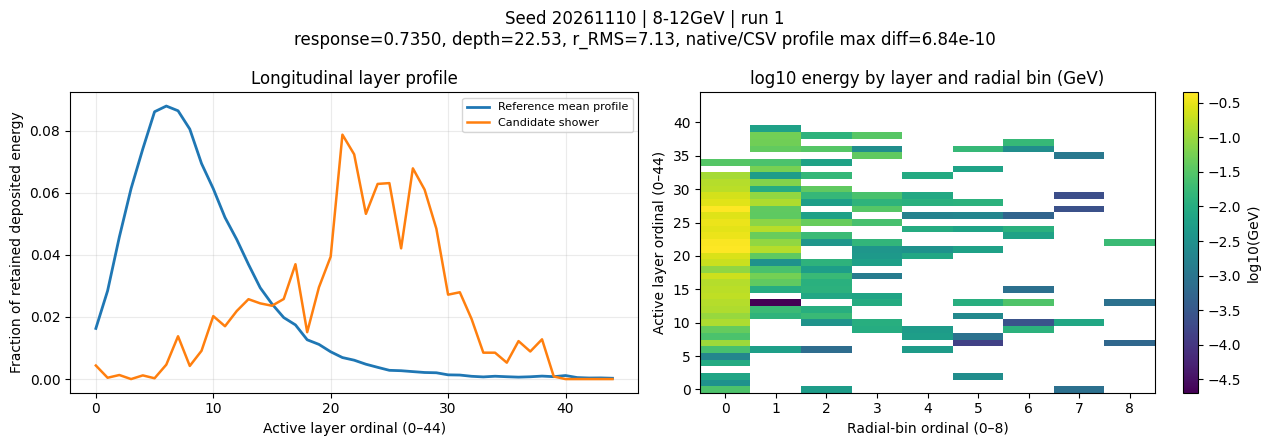

{'event_id': 'gen:electron:8-12GeV:1:58', 'seed': 20261110, 'incident_energy_GeV': 10.3990224609375, 'raw_native_total_GeV': 7.643424427007631, 'thresholded_total_GeV': 7.643424427007631, 'response_recomputed': 0.7350137434282025, 'max_layer_profile_difference_vs_CSV': 6.837829746864088e-10}


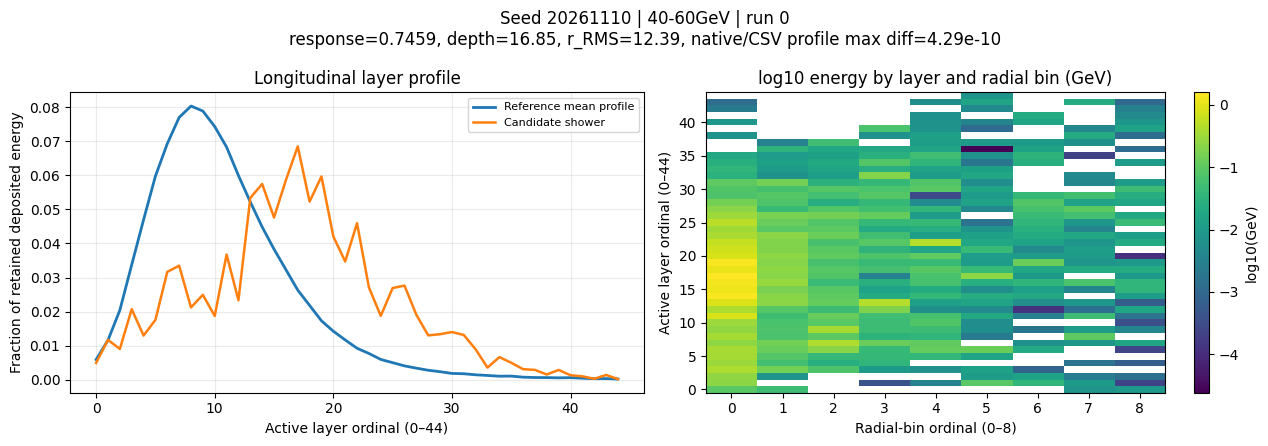

{'event_id': 'gen:electron:40-60GeV:0:113', 'seed': 20261110, 'incident_energy_GeV': 43.0477890625, 'raw_native_total_GeV': 32.110018720783046, 'thresholded_total_GeV': 32.110018720783046, 'response_recomputed': 0.7459156305138765, 'max_layer_profile_difference_vs_CSV': 4.285579668916739e-10}


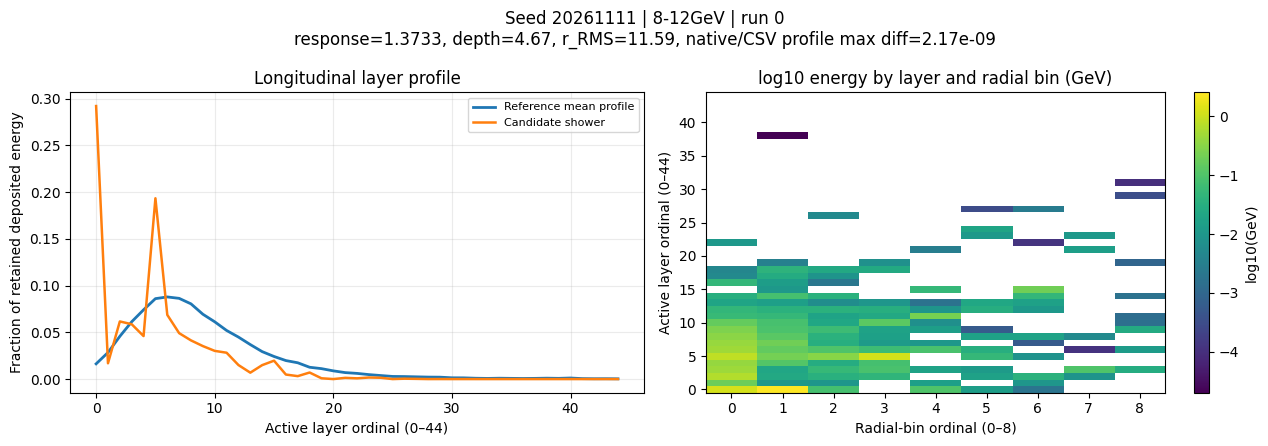

{'event_id': 'gen:electron:8-12GeV:0:61', 'seed': 20261111, 'incident_energy_GeV': 9.771068359375, 'raw_native_total_GeV': 13.418579697230598, 'thresholded_total_GeV': 13.418579697230598, 'response_recomputed': 1.3732970852011221, 'max_layer_profile_difference_vs_CSV': 2.166467727438004e-09}


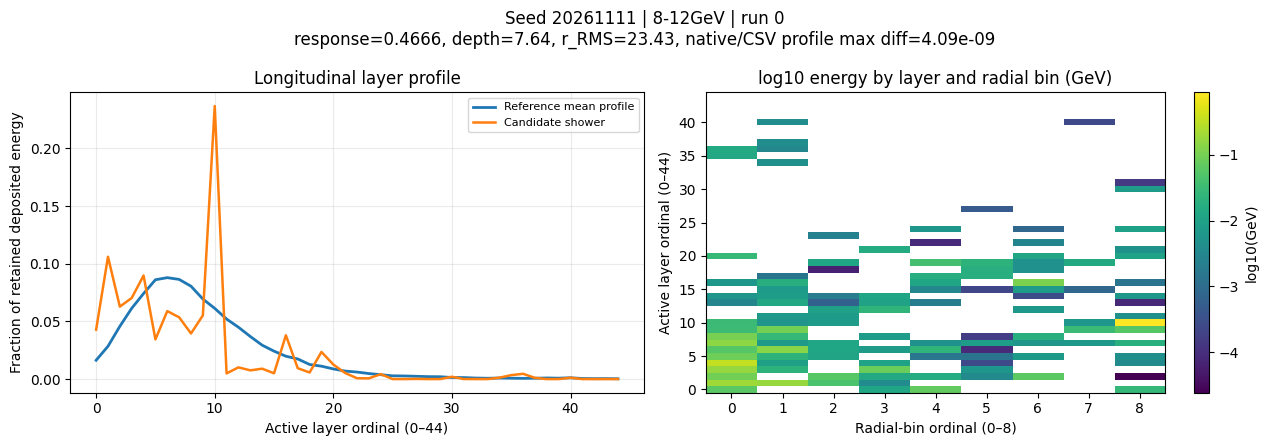

{'event_id': 'gen:electron:8-12GeV:0:200', 'seed': 20261111, 'incident_energy_GeV': 8.44853125, 'raw_native_total_GeV': 3.9422010180423968, 'thresholded_total_GeV': 3.9422010180423968, 'response_recomputed': 0.466613770061204, 'max_layer_profile_difference_vs_CSV': 4.0944273249632346e-09}


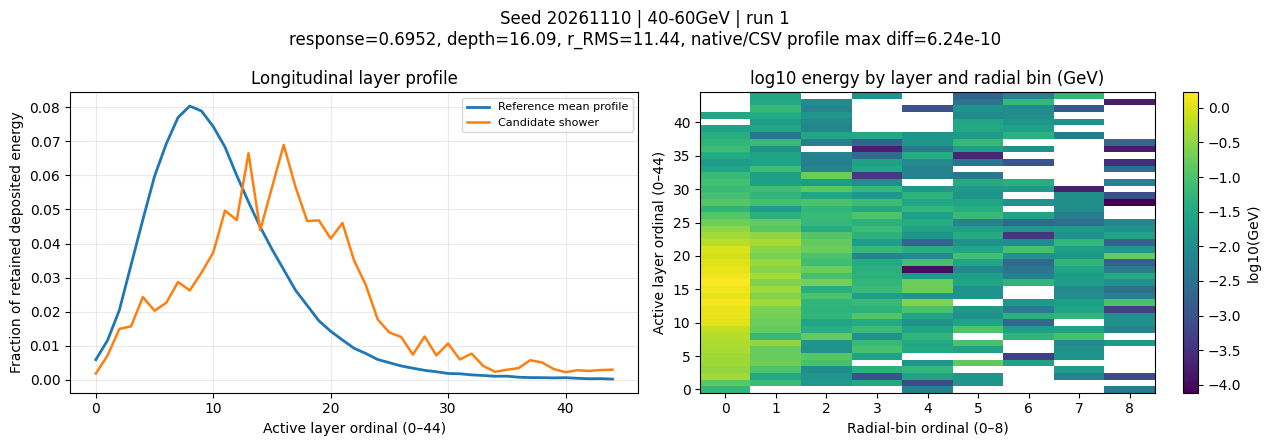

{'event_id': 'gen:electron:40-60GeV:1:31', 'seed': 20261110, 'incident_energy_GeV': 51.41228125, 'raw_native_total_GeV': 35.742966264610004, 'thresholded_total_GeV': 35.742966264610004, 'response_recomputed': 0.6952223359007242, 'max_layer_profile_difference_vs_CSV': 6.235922542230377e-10}


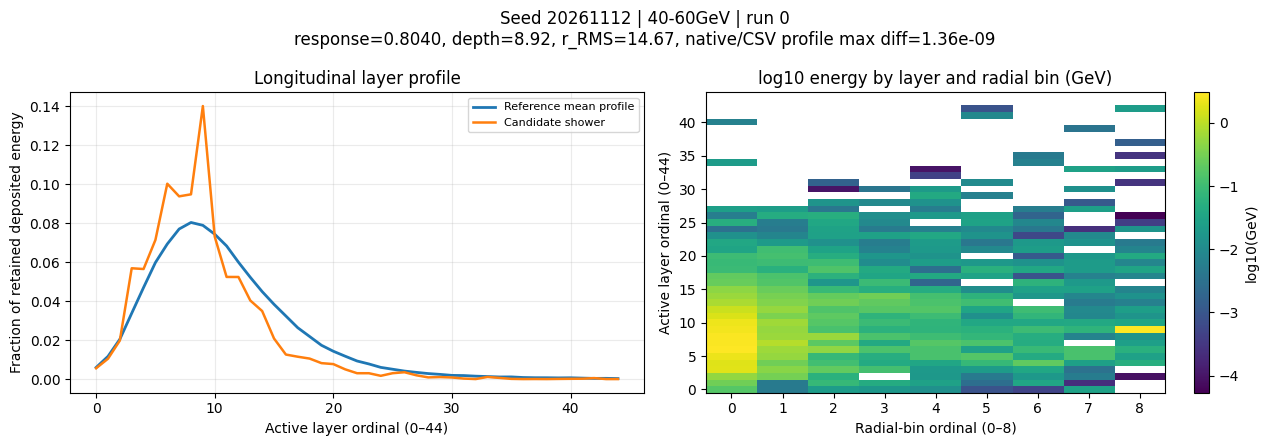

{'event_id': 'gen:electron:40-60GeV:0:120', 'seed': 20261112, 'incident_energy_GeV': 58.19437109375, 'raw_native_total_GeV': 46.789396391211994, 'thresholded_total_GeV': 46.789396391211994, 'response_recomputed': 0.8040192807623127, 'max_layer_profile_difference_vs_CSV': 1.3623003281004742e-09}


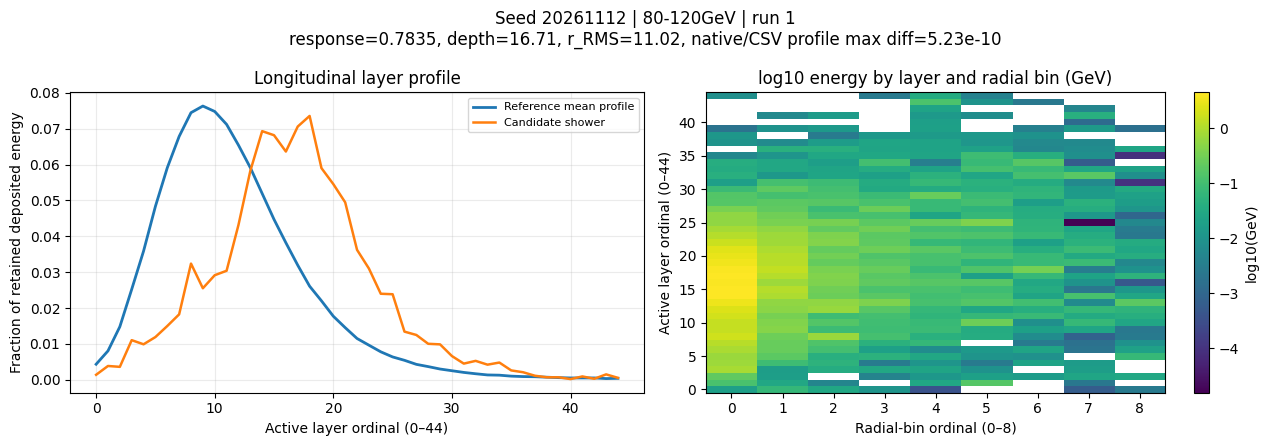

{'event_id': 'gen:electron:80-120GeV:1:48', 'seed': 20261112, 'incident_energy_GeV': 114.93740625000001, 'raw_native_total_GeV': 90.05139831635825, 'thresholded_total_GeV': 90.05139831635825, 'response_recomputed': 0.7834820817209649, 'max_layer_profile_difference_vs_CSV': 5.234395555886451e-10}


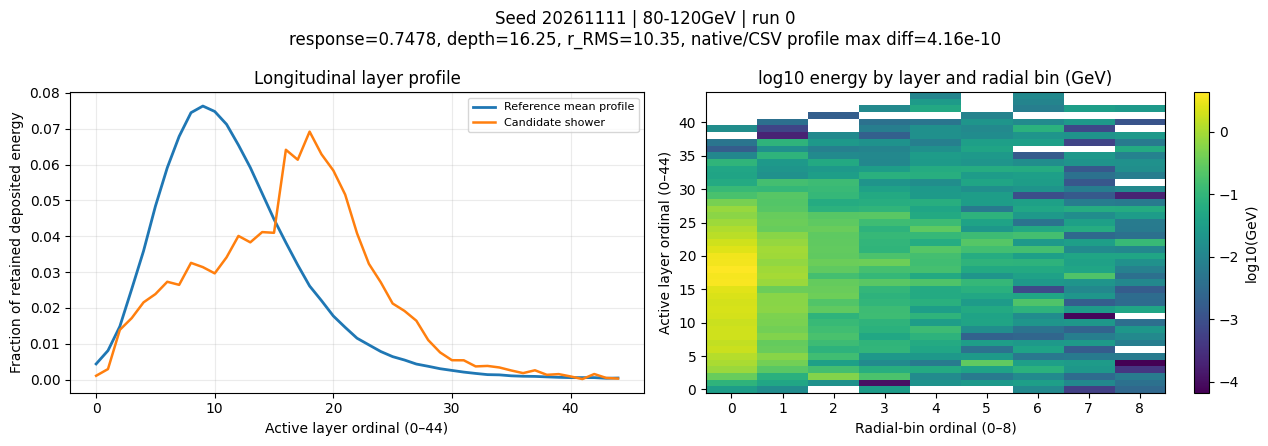

{'event_id': 'gen:electron:80-120GeV:0:255', 'seed': 20261111, 'incident_energy_GeV': 115.01321875000001, 'raw_native_total_GeV': 86.00433542521023, 'thresholded_total_GeV': 86.00433542521023, 'response_recomputed': 0.7477778324955384, 'max_layer_profile_difference_vs_CSV': 4.1569470782265583e-10}


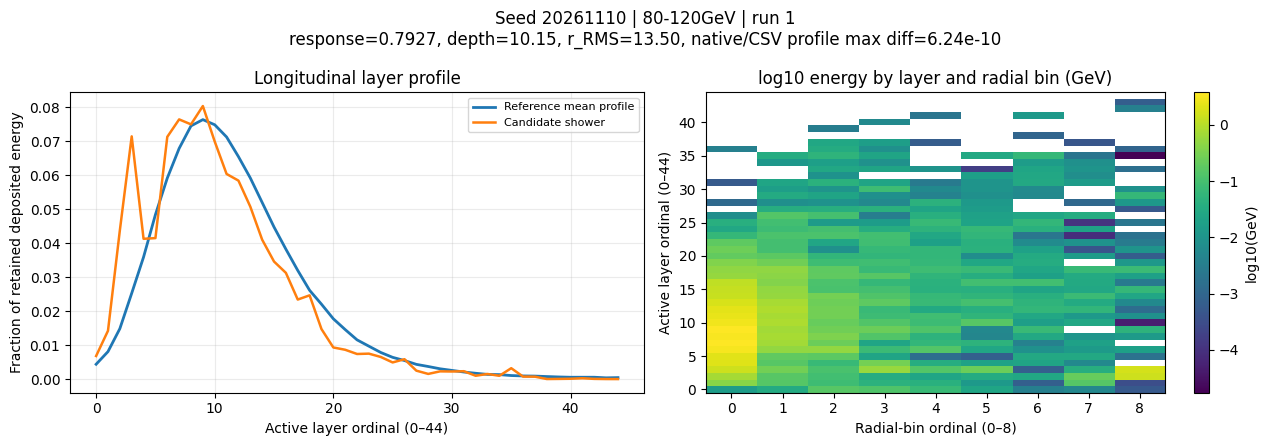

{'event_id': 'gen:electron:80-120GeV:1:258', 'seed': 20261110, 'incident_energy_GeV': 80.47725, 'raw_native_total_GeV': 63.79319170089366, 'thresholded_total_GeV': 63.79319170089366, 'response_recomputed': 0.792686028671378, 'max_layer_profile_difference_vs_CSV': 6.243818170825755e-10}
Candidate layer-profile rows: 405
Candidate layer-radial rows: 3645


In [ ]:
candidate_layer_rows = []
candidate_radial_rows = []

for cand_idx, cand in selected_candidates.iterrows():
    seed = int(cand["generation_seed"])
    stratum = cand["stratum"]
    run_id = int(cand["run"])
    event_id = str(cand["event_id"])

    native, npz_energy = load_generator_event_native(seed, stratum, run_id, event_id)
    raw_total = float(native.sum())
    thresholded = np.where(native >= EXPECTED_CUTOFF_GEV, native, 0.0)
    kept_total = float(thresholded.sum())

    cube = thresholded.reshape(N_LAYERS, N_ANGLES, N_RADIAL)
    layer_energy = cube.sum(axis=(1, 2))
    layer_fraction = layer_energy / kept_total if kept_total > 0 else np.zeros(N_LAYERS)
    layer_radial_energy = cube.sum(axis=1)  # (layer, radial bin), summed over angle

    # Cross-check native array against the event-level CSV metrics.
    csv_row = gen[
        (gen.generation_seed == seed) &
        (gen.stratum == stratum) &
        (gen.run == run_id) &
        (gen.event_id.astype(str) == event_id)
    ]
    if len(csv_row) != 1:
        raise AssertionError(f"Could not uniquely match event metrics for {event_id}")
    csv_row = csv_row.iloc[0]
    csv_profile = np.array([csv_row[c] for c in layer_cols], dtype=float)
    max_profile_diff = float(np.max(np.abs(layer_fraction - csv_profile)))
    if max_profile_diff > 2e-5:
        raise AssertionError(
            f"Native/CSV layer profile mismatch for {event_id}: {max_profile_diff}"
        )

    response_native = kept_total / npz_energy if npz_energy > 0 else np.nan

    for layer in range(N_LAYERS):
        candidate_layer_rows.append({
            "generation_seed": seed, "stratum": stratum, "run": run_id,
            "event_id": event_id, "layer_ordinal": layer,
            "layer_energy_GeV": layer_energy[layer],
            "layer_fraction": layer_fraction[layer],
        })
        for radial_bin in range(N_RADIAL):
            candidate_radial_rows.append({
                "generation_seed": seed, "stratum": stratum, "run": run_id,
                "event_id": event_id, "layer_ordinal": layer,
                "radial_bin": radial_bin,
                "radial_low_XML": radial_edges_common[radial_bin],
                "radial_high_XML": radial_edges_common[radial_bin + 1],
                "energy_GeV": layer_radial_energy[layer, radial_bin],
            })

    # Plot this candidate's 45-layer profile and layer-by-radial heatmap.
    ref_profile = profile_vectors[(stratum, "reference")]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    layers = np.arange(N_LAYERS)
    axes[0].plot(layers, ref_profile, linewidth=2, label="Reference mean profile")
    axes[0].plot(layers, layer_fraction, linewidth=1.8, label="Candidate shower")
    axes[0].set_xlabel("Active layer ordinal (0–44)")
    axes[0].set_ylabel("Fraction of retained deposited energy")
    axes[0].set_title("Longitudinal layer profile")
    axes[0].grid(alpha=0.25)
    axes[0].legend(fontsize=8)

    heat = np.full(layer_radial_energy.shape, np.nan, dtype=float)
    positive_cells = layer_radial_energy > 0
    heat[positive_cells] = np.log10(layer_radial_energy[positive_cells])
    im = axes[1].imshow(heat, origin="lower", aspect="auto", interpolation="nearest")
    axes[1].set_xlabel("Radial-bin ordinal (0–8)")
    axes[1].set_ylabel("Active layer ordinal (0–44)")
    axes[1].set_title("log10 energy by layer and radial bin (GeV)")
    fig.colorbar(im, ax=axes[1], label="log10(GeV)")
    fig.suptitle(
        f"Seed {seed} | {stratum} | run {run_id}\n"
        f"response={response_native:.4f}, depth={csv_row['depth_layer']:.2f}, "
        f"r_RMS={csv_row['r_rms']:.2f}, native/CSV profile max diff={max_profile_diff:.2e}"
    )
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"candidate_{cand_idx+1}_{stratum.replace('-', '_')}_seed{seed}.png", dpi=160)
    plt.show()

    print({
        "event_id": event_id,
        "seed": seed,
        "incident_energy_GeV": npz_energy,
        "raw_native_total_GeV": raw_total,
        "thresholded_total_GeV": kept_total,
        "response_recomputed": response_native,
        "max_layer_profile_difference_vs_CSV": max_profile_diff,
    })

candidate_layer_df = pd.DataFrame(candidate_layer_rows)
candidate_radial_df = pd.DataFrame(candidate_radial_rows)
print("Candidate layer-profile rows:", len(candidate_layer_df))
print("Candidate layer-radial rows:", len(candidate_radial_df))

## 15. Run-to-run stability of response and shape observables

In [ ]:
stability_rows = []
for stratum in EXPECTED_STRATA:
    for seed in EXPECTED_SEEDS:
        sub = gen[(gen.stratum == stratum) & (gen.generation_seed == seed)]
        for metric in ["response", "occupancy", "depth_layer", "r_rms", "r_sigma"]:
            x = sub[metric].to_numpy(dtype=float)
            stability_rows.append({
                "stratum": stratum, "generation_seed": seed, "observable": metric,
                "n": len(x), "mean": x.mean(), "std": x.std(ddof=1),
                "q05": np.quantile(x, 0.05), "median": np.quantile(x, 0.50),
                "q95": np.quantile(x, 0.95), "q99": np.quantile(x, 0.99),
            })
stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(5))

,stratum,generation_seed,observable,n,mean,std,q05,median,q95,q99
0,8-12GeV,20261110,response,600,0.74607,0.11182,0.55187,0.74791,0.92274,0.97934
1,8-12GeV,20261110,occupancy,600,0.06881,0.00898,0.05477,0.06844,0.08396,0.09106
2,8-12GeV,20261110,depth_layer,600,8.57859,1.31332,6.80010,8.42234,10.72455,11.85183
3,8-12GeV,20261110,r_rms,600,10.44845,1.78853,8.12646,10.13123,13.84759,16.41211
4,8-12GeV,20261110,r_sigma,600,7.81629,1.30258,6.04097,7.67710,10.26538,11.64581
5,8-12GeV,20261111,response,600,0.74606,0.11407,0.56165,0.74712,0.92020,0.96763
6,8-12GeV,20261111,occupancy,600,0.06893,0.00886,0.05493,0.06898,0.08364,0.08951
7,8-12GeV,20261111,depth_layer,600,8.54085,1.25507,6.73786,8.42616,10.78809,11.84865
8,8-12GeV,20261111,r_rms,600,10.47106,1.82390,8.11313,10.10188,13.68207,16.29611
9,8-12GeV,20261111,r_sigma,600,7.82760,1.28816,6.04232,7.63104,10.06463,11.59649


## 16. Interpretation checklist

In [ ]:
# These flags are generated from the inspected files; they do not infer physical validity.
interpretation_rows = []
for stratum in EXPECTED_STRATA:
    for metric in OUTLIER_METRICS:
        sub = outlier_counts_df[outlier_counts_df.stratum == stratum]
        s = sub[sub.metric == metric]
        if len(s):
            interpretation_rows.append({
                "stratum": stratum,
                "metric": metric,
                "generated_outside_reference_1_99_range_across_all_seeds": int(s.outside_reference_q01_q99.sum()),
                "generated_n_across_all_seeds": int(s.n_generated.sum()),
                "comment": "Inspect candidates; an outside-envelope value is not automatically unphysical."
            })
interpretation_df = pd.DataFrame(interpretation_rows)
display(interpretation_df)

print("\nImportant caveats:")
print("1. Reference sample size is 300 per energy window; rare-tail limits are uncertain.")
print("2. Candidate screening uses reference quantiles and robust MAD scores; no showers are deleted.")
print("3. Layer indices are ordinals, not millimetres or a measured physical z coordinate.")
print("4. The reference/checkpoint training and selection independence remains unverified.")
print("5. Scale-only is a response/shape control built from fixed calibration donors, not a full independent shower generator.")

,stratum,metric,generated_outside_reference_1_99_range_across_all_seeds,generated_n_across_all_seeds,comment
0,8-12GeV,response,68,1800,Inspect candidates; an outside-envelope value ...
1,8-12GeV,deposited_GeV,54,1800,Inspect candidates; an outside-envelope value ...
2,8-12GeV,occupancy,41,1800,Inspect candidates; an outside-envelope value ...
3,8-12GeV,depth_layer,37,1800,Inspect candidates; an outside-envelope value ...
4,8-12GeV,r_rms,23,1800,Inspect candidates; an outside-envelope value ...
5,8-12GeV,r_sigma,23,1800,Inspect candidates; an outside-envelope value ...
6,40-60GeV,response,87,1800,Inspect candidates; an outside-envelope value ...
7,40-60GeV,deposited_GeV,54,1800,Inspect candidates; an outside-envelope value ...
8,40-60GeV,occupancy,54,1800,Inspect candidates; an outside-envelope value ...
9,40-60GeV,depth_layer,51,1800,Inspect candidates; an outside-envelope value ...



Important caveats:
1. Reference sample size is 300 per energy window; rare-tail limits are uncertain.
2. Candidate screening uses reference quantiles and robust MAD scores; no showers are deleted.
3. Layer indices are ordinals, not millimetres or a measured physical z coordinate.
4. The reference/checkpoint training and selection independence remains unverified.
5. Scale-only is a response/shape control built from fixed calibration donors, not a full independent shower generator.


## 17. Export all tables and plots

In [ ]:
# Save compatibility, summaries, outlier tables and layer-profile tables.
compatibility_df.to_csv(OUTPUT_DIR / "run_compatibility.csv", index=False)
counts_df.to_csv(OUTPUT_DIR / "sample_counts_by_seed.csv", index=False)
summary_df.to_csv(OUTPUT_DIR / "event_observable_statistics_by_seed.csv", index=False)
metric_flags_df.to_csv(OUTPUT_DIR / "generator_metric_reference_envelope_flags.csv", index=False)
outlier_counts_df.to_csv(OUTPUT_DIR / "outlier_counts_by_metric_seed_energy.csv", index=False)
candidates_df.to_csv(OUTPUT_DIR / "generator_outlier_candidate_events.csv", index=False)
extremes_df.to_csv(OUTPUT_DIR / "generator_extreme_events.csv", index=False)
layer_profile_df.to_csv(OUTPUT_DIR / "layer_profile_by_layer_seed_method.csv", index=False)
phase_summary_df.to_csv(OUTPUT_DIR / "early_middle_late_profile_summary.csv", index=False)
layer_distance_df.to_csv(OUTPUT_DIR / "layer_profile_distance_from_reference.csv", index=False)
candidate_layer_df.to_csv(OUTPUT_DIR / "selected_candidate_layer_profiles.csv", index=False)
candidate_radial_df.to_csv(OUTPUT_DIR / "selected_candidate_layer_radial_energy.csv", index=False)
stability_df.to_csv(OUTPUT_DIR / "generation_seed_stability.csv", index=False)
interpretation_df.to_csv(OUTPUT_DIR / "interpretation_checklist.csv", index=False)

# Save manifest summary and provenance warning.
manifest_summary = []
for seed, rec in sorted(runs.items()):
    m = rec["manifest"]
    manifest_summary.append({
        "generation_seed": seed,
        "partition_seed": m["seed_streams"]["partition_seed"],
        "baseline_seed": m["seed_streams"]["baseline_seed"],
        "analysis_seed": m["seed_streams"]["analysis_seed"],
        "partition_sha256": m["partition_sha256"]["electron"],
        "reference_sha256": m["reference_files"]["electron"]["sha256"],
        "checkpoint_sha256": m["checkpoints"]["electron"]["sha256"],
        "analysis_cut_GeV": m["analysis_cut_GeV_overrides"]["electron"],
        "reference_is_unseen_by_checkpoint": m.get("reference_is_unseen_by_checkpoint", False),
    })
pd.DataFrame(manifest_summary).to_csv(OUTPUT_DIR / "manifest_compatibility_summary.csv", index=False)

# Package results for sharing.
import shutil
zip_path = Path("/content/electron_outlier_layer_profile_results.zip")
if zip_path.exists():
    zip_path.unlink()
shutil.make_archive(str(zip_path.with_suffix("")), "zip", OUTPUT_DIR)
print("Saved results to:", zip_path)
files.download(str(zip_path))

Saved results to: /content/electron_outlier_layer_profile_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. How to read the results

### Outlier tables

- `generator_metric_reference_envelope_flags.csv`: one row per generated shower and metric, indicating whether it is below the reference 1st percentile or above the reference 99th percentile.
- `outlier_counts_by_metric_seed_energy.csv`: tail counts by metric, generation seed and energy window.
- `generator_outlier_candidate_events.csv`: unique event-level shortlist of showers worth inspecting.
- `generator_extreme_events.csv`: minimum/maximum examples for response, depth, radial RMS and occupancy for each seed and energy.

### Layer-profile tables and plots

- `layer_profile_by_layer_seed_method.csv`: mean, standard deviation and bootstrap interval for each of 45 layers.
- `layer_profile_distance_from_reference.csv`: L1 and total-variation distances between mean profiles.
- `early_middle_late_profile_summary.csv`: energy fractions in active-layer ordinal groups 0–9, 10–24 and 25–44.
- `selected_candidate_layer_profiles.csv` and `selected_candidate_layer_radial_energy.csv`: layer and radial details for the selected candidate events.

### What counts as a useful conclusion?

1. If all seeds show the same layer-profile difference, it is more likely to be a repeatable modelling pattern than one random batch fluctuation.
2. If only one or two showers drive the difference, report a rare-tail issue rather than a population-wide mismatch.
3. Compare each candidate against the reference distribution at the same energy window.
4. Do not delete outliers to improve agreement. Keep full-sample results and report any sensitivity analysis separately.
5. The notebook is a diagnostic closeout. It does not establish reference/checkpoint independence or prove that a candidate shower is physically impossible.
